# 03 — EDA, Feature Engineering & Preprocessing
Input: `data/processed/uber_cleaned.csv`. Outputs: `uber_features.csv`, `X_train/X_test/y_train/y_test.csv`,
`src/features.py`, `src/preprocessing.py`, `reports/feature_schema.md`.

In [1]:
# --- Project setup (works locally and on Colab after cloning the repo) ---
import os, sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("Project root:", ROOT)

Project root: D:\ML


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.features import build_features, select_features, FEATURE_COLUMNS, TARGET, LEAKAGE_COLUMNS

df = pd.read_csv("data/processed/uber_cleaned.csv", parse_dates=["pickup_datetime"])
df = build_features(df)

print(df.shape)
display(df.head())
df.info()
FIG = "reports/figures/"

(307252, 27)


,id,hour,day,month,pickup_datetime,source,destination,name,price,distance,...,windSpeed,windGust,visibility,dewPoint,pressure,windBearing,cloudCover,uvIndex,day_of_week,is_weekend
0,5f3ee457-8e98-4b4b-9582-e6bc3a3ad0e7,3,26,11,2018-11-26 03:40:46,Boston University,West End,Lyft,10.5,3.06,...,0.51,0.8,1.685,39.62,1014.1,57,1.0,0,0,0
1,e4d3df16-8b2b-4748-bf2b-f3b4e62c0ba2,3,26,11,2018-11-26 03:40:46,Boston University,West End,Lux,22.5,3.06,...,0.51,0.8,1.685,39.62,1014.1,57,1.0,0,0,0
2,ef4771c2-c88d-4730-aaf7-a95751e9d27e,3,26,11,2018-11-26 03:40:46,Boston University,Theatre District,Lux Black XL,34.0,3.03,...,0.51,0.8,1.685,39.62,1014.1,57,1.0,0,0,0
3,a8b37ec2-b380-47da-8269-590dfaaffdbf,3,26,11,2018-11-26 03:40:46,North End,West End,Lux Black,19.5,1.23,...,0.51,0.8,1.685,39.62,1014.1,57,1.0,0,0,0
4,b5a8df24-a8bf-4450-9086-fcd699cb4fbe,3,26,11,2018-11-26 03:40:46,Fenway,West End,Lyft XL,16.5,2.83,...,0.51,0.8,1.685,39.62,1014.1,57,1.0,0,0,0


<class 'pandas.DataFrame'>
RangeIndex: 307252 entries, 0 to 307251
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   id                   307252 non-null  str           
 1   hour                 307252 non-null  int32         
 2   day                  307252 non-null  int64         
 3   month                307252 non-null  int64         
 4   pickup_datetime      307252 non-null  datetime64[us]
 5   source               307252 non-null  str           
 6   destination          307252 non-null  str           
 7   name                 307252 non-null  str           
 8   price                307252 non-null  float64       
 9   distance             307252 non-null  float64       
 10  surge_multiplier     307252 non-null  float64       
 11  temperature          307252 non-null  float64       
 12  apparentTemperature  307252 non-null  float64       
 13  short_summary        3072

## A. Surge multiplier distribution

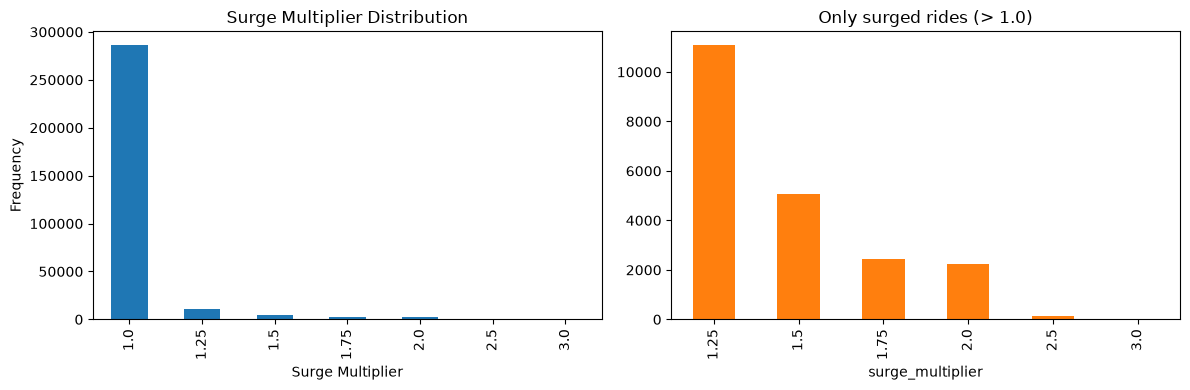

surge_multiplier
1.00    93.17
1.25     3.61
1.50     1.65
1.75     0.79
2.00     0.73
2.50     0.05
3.00     0.00
Name: proportion, dtype: float64


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df[TARGET].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Surge Multiplier Distribution"); axes[0].set_xlabel("Surge Multiplier"); axes[0].set_ylabel("Frequency")
df.loc[df[TARGET] > 1, TARGET].value_counts().sort_index().plot.bar(ax=axes[1], color="tab:orange")
axes[1].set_title("Only surged rides (> 1.0)")
plt.tight_layout(); plt.savefig(FIG + "03_target_distribution.png", dpi=100); plt.show()

print((df[TARGET].value_counts(normalize=True).sort_index() * 100).round(2))

**Strong imbalance:** about 93% of rides have no surge (1.0). Because this is regression, SMOTE does not apply.
How we handle it:
1. A time-ordered split, so the test set keeps the real surge rate.
2. Evaluation also reports the error **on surged rides only** (`final_evaluation.md`), so a model that always predicts
   1.0 cannot look good.
3. RMSE is the main metric. It penalises big misses on high surges.

## B. Surge by hour of day

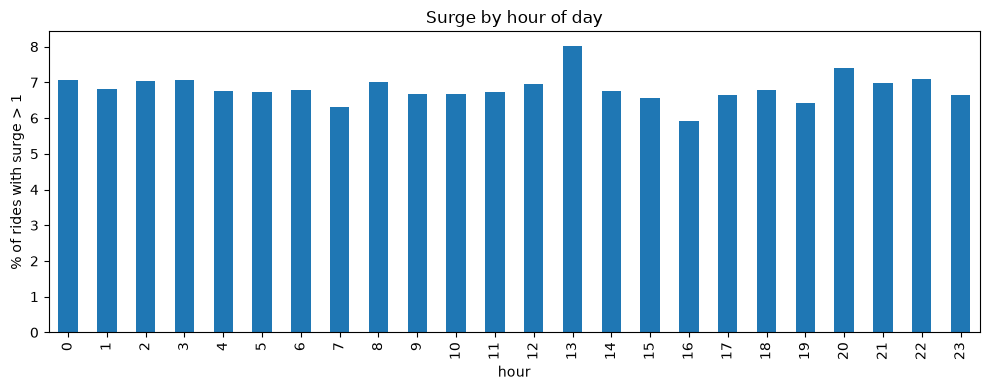

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
mean_surge,1.031,1.032,1.033,1.031,1.030,1.031,1.031,1.029,1.031,1.032,...,1.031,1.031,1.029,1.030,1.031,1.029,1.033,1.032,1.032,1.03
pct_surged,7.071,6.802,7.030,7.066,6.745,6.743,6.791,6.298,7.021,6.667,...,6.752,6.560,5.915,6.658,6.777,6.433,7.393,6.994,7.085,6.64


In [4]:
by_hour = df.groupby("hour")[TARGET].agg(mean_surge="mean", pct_surged=lambda s: (s > 1).mean() * 100)
fig, ax = plt.subplots(figsize=(10, 4))
by_hour["pct_surged"].plot.bar(ax=ax)
ax.set_ylabel("% of rides with surge > 1"); ax.set_title("Surge by hour of day")
plt.tight_layout(); plt.savefig(FIG + "03_surge_by_hour.png", dpi=100); plt.show()
display(by_hour.round(3).T)

## C. Weekday vs weekend

In [5]:
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day = df.groupby("day_of_week")[TARGET].agg(mean_surge="mean", pct_surged=lambda s: (s > 1).mean() * 100, rides="size")
by_day.index = days
display(by_day.round(3))
display(df.groupby("is_weekend")[TARGET].agg(mean_surge="mean", pct_surged=lambda s: (s > 1).mean() * 100).round(3))

,mean_surge,pct_surged,rides
Mon,1.031,6.818,54895
Tue,1.032,6.926,55383
Wed,1.032,6.929,32759
Thu,1.031,6.936,43437
Fri,1.031,6.629,40054
Sat,1.031,6.802,40179
Sun,1.031,6.721,40545


,mean_surge,pct_surged
is_weekend,,
0,1.031,6.850
1,1.031,6.761


## D. Distance vs surge

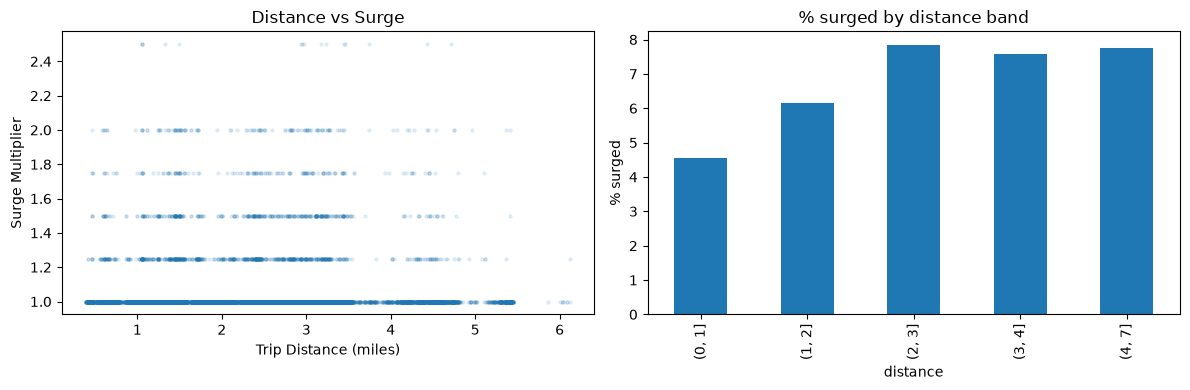

In [6]:
sample = df.sample(20000, random_state=42)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(sample["distance"], sample[TARGET], alpha=0.1, s=5)
axes[0].set_xlabel("Trip Distance (miles)"); axes[0].set_ylabel("Surge Multiplier"); axes[0].set_title("Distance vs Surge")
df.groupby(pd.cut(df["distance"], [0, 1, 2, 3, 4, 7]), observed=True)[TARGET].apply(lambda s: (s > 1).mean() * 100).plot.bar(ax=axes[1])
axes[1].set_ylabel("% surged"); axes[1].set_title("% surged by distance band")
plt.tight_layout(); plt.savefig(FIG + "03_distance_vs_surge.png", dpi=100); plt.show()

## E. Correlation heatmap (numeric columns)

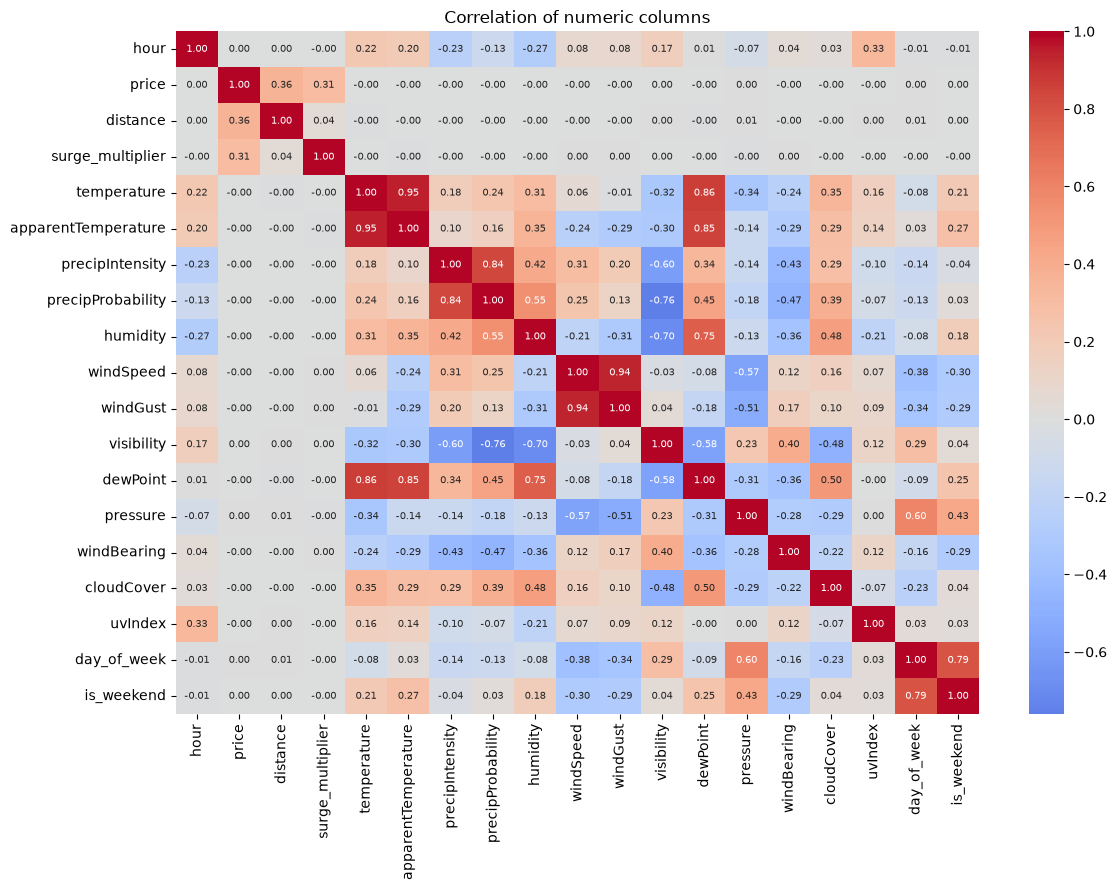

price                  0.308
distance               0.040
pressure              -0.005
windSpeed              0.005
apparentTemperature   -0.005
uvIndex               -0.004
windGust               0.004
precipProbability     -0.004
windBearing            0.003
cloudCover            -0.003
temperature           -0.003
dewPoint              -0.003
day_of_week           -0.003
is_weekend            -0.002
visibility             0.002
humidity              -0.002
precipIntensity       -0.002
hour                  -0.000
Name: surge_multiplier, dtype: float64


In [7]:
num = df.select_dtypes("number").drop(columns=["day", "month"], errors="ignore")
plt.figure(figsize=(12, 9))
sns.heatmap(num.corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation of numeric columns")
plt.tight_layout(); plt.savefig(FIG + "03_correlation.png", dpi=100); plt.show()
print(num.corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False).round(3))

- No single numeric column has a strong **linear** correlation with surge. Surge depends on supply and demand,
  which the dataset does not observe. We expect modest R² and non-linear models to do better.
- Weather columns are strongly correlated with each other (`temperature` / `apparentTemperature` / `dewPoint`,
  `windSpeed` / `windGust`, `precipIntensity` / `precipProbability`). We keep one per group.

## F. Weather, area and product

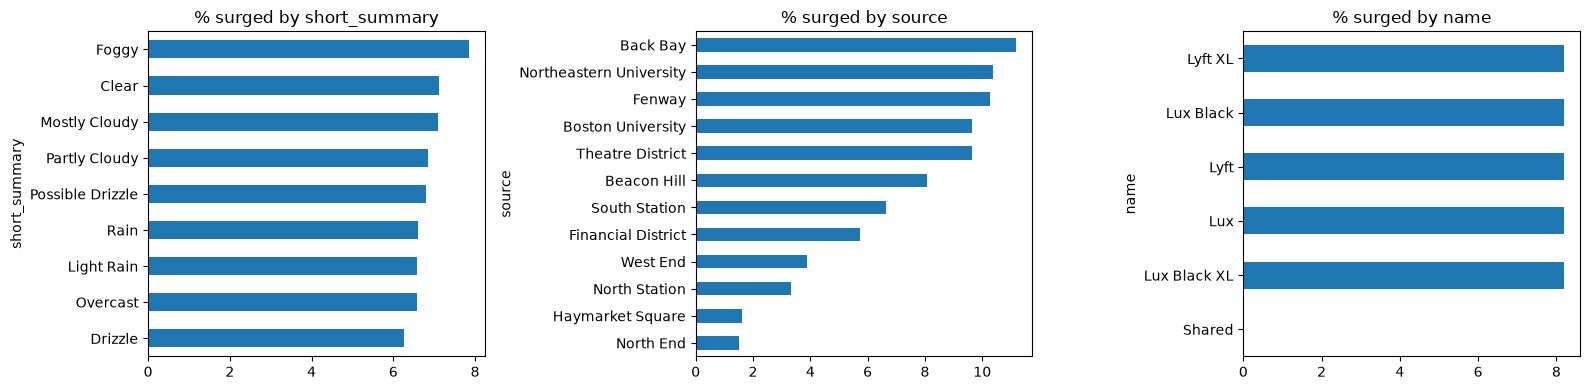

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["short_summary", "source", "name"]):
    (df.groupby(col)[TARGET].apply(lambda s: (s > 1).mean() * 100).sort_values()).plot.barh(ax=ax)
    ax.set_title(f"% surged by {col}")
plt.tight_layout(); plt.savefig(FIG + "03_surge_by_category.png", dpi=100); plt.show()

- `name`: **Shared never surges**, and the other products surge at the same rate. This is a strong, legitimate feature.
- `source` / `destination`: surge rates differ by area. These are useful.
- No traffic, driver-supply or request-count columns exist, so nothing was invented for them.

## G. Leakage check — `price`

In [9]:
display(df.groupby(["name", TARGET])["price"].mean().unstack().round(2))

surge_multiplier,1.00,1.25,1.50,1.75,2.00,2.50,3.00
name,,,,,,,
Lux,17.11,21.50,26.22,30.48,34.34,NaN,NaN
Lux Black,22.18,28.10,34.31,40.02,45.51,NaN,NaN
Lux Black XL,31.10,39.26,47.63,56.11,63.61,NaN,NaN
Lyft,9.28,11.51,13.73,15.66,17.33,22.52,29.75
Lyft XL,14.74,18.48,22.58,26.10,28.96,37.90,50.92
Shared,6.03,NaN,NaN,NaN,NaN,NaN,NaN


For the same product, the average price rises with the surge, because **price = base fare × surge**.
Price is only known after the surge is applied, so it is excluded from the features.

## Feature selection

In [10]:
print("Features:", FEATURE_COLUMNS)
print("Target:", TARGET)
excluded = [c for c in df.columns if c not in FEATURE_COLUMNS + [TARGET]]
print("Excluded:", excluded)
uber_features = df[["pickup_datetime"] + FEATURE_COLUMNS + [TARGET]]
uber_features.to_csv("data/processed/uber_features.csv", index=False)
uber_features.shape

Features: ['source', 'destination', 'name', 'short_summary', 'distance', 'hour', 'day_of_week', 'is_weekend', 'temperature', 'precipIntensity', 'humidity', 'windSpeed', 'visibility', 'cloudCover']
Target: surge_multiplier
Excluded: ['id', 'day', 'month', 'pickup_datetime', 'price', 'apparentTemperature', 'precipProbability', 'windGust', 'dewPoint', 'pressure', 'windBearing', 'uvIndex']


(307252, 16)

## Train / test split — time ordered
The data has a real timestamp, so we sort it oldest → newest and use the first 80% for training and the last 20%
for testing. This simulates predicting future rides and avoids putting rows from the same API request in both sets.
Nothing is fitted before the split. Imputer, scaler and encoder are fitted later, inside the model Pipeline,
on training data only.

In [11]:
uber_features = uber_features.sort_values("pickup_datetime").reset_index(drop=True)
cut = int(len(uber_features) * 0.8)
train, test = uber_features.iloc[:cut], uber_features.iloc[cut:]

X_train, y_train = select_features(train), train[TARGET]
X_test, y_test = select_features(test), test[TARGET]

print("Train:", X_train.shape, train["pickup_datetime"].min(), "->", train["pickup_datetime"].max())
print("Test: ", X_test.shape, test["pickup_datetime"].min(), "->", test["pickup_datetime"].max())
print("Surged % train / test:", round((y_train > 1).mean() * 100, 2), "/", round((y_test > 1).mean() * 100, 2))

X_train.to_csv("data/processed/X_train.csv", index=False)
X_test.to_csv("data/processed/X_test.csv", index=False)
y_train.to_csv("data/processed/y_train.csv", index=False)
y_test.to_csv("data/processed/y_test.csv", index=False)

Train: (245801, 14) 2018-11-26 03:40:46 -> 2018-12-15 17:05:12
Test:  (61451, 14) 2018-12-15 17:05:12 -> 2018-12-18 19:15:10
Surged % train / test: 6.79 / 6.98


## Preprocessing pipeline check (unfitted → fit on train only)

In [12]:
from src.preprocessing import make_preprocessor

pre = make_preprocessor(X_train)
print(pre)
Xt = pre.fit_transform(X_train)          # demo only: fit on TRAIN
print("Transformed train shape:", Xt.shape)
print(pre.get_feature_names_out()[:15])

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['distance', 'hour', 'day_of_week',
                                  'is_weekend', 'temperature',
                                  'precipIntensity', 'humidity', 'windSpeed',
                                  'visibility', 'cloudCover']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
               

Transformed train shape: (245801, 49)
['numeric__distance' 'numeric__hour' 'numeric__day_of_week'
 'numeric__is_weekend' 'numeric__temperature' 'numeric__precipIntensity'
 'numeric__humidity' 'numeric__windSpeed' 'numeric__visibility'
 'numeric__cloudCover' 'categorical__source_Back Bay'
 'categorical__source_Beacon Hill' 'categorical__source_Boston University'
 'categorical__source_Fenway' 'categorical__source_Financial District']
